## Prepare environment

### Load packages

In [29]:
# ## Create a vector of the required packages for this analysis
# req_packages <- c("BiocManager", "devtools")

# ## load the packages, quietly
# invisible(suppressWarnings(suppressMessages(
#     lapply(req_packages, require, character.only = TRUE)
# )))

# BiocManager::install("anndataR")
# BiocManager::install("rhdf5")
# devtools::install_github('immunogenomics/presto')

In [2]:
## Create a vector of the required packages for this analysis
req_packages <- c("anndataR", "MAST", "presto", "rhdf5", "scater", "Seurat", "tidyverse", "zellkonverter")

## load the packages, quietly
invisible(suppressWarnings(suppressMessages(
    lapply(req_packages, require, character.only = TRUE)
)))

### Load data

In [3]:
## load in single-cell RNA-seq results as singlecell experiment
sce_sce <- readH5AD("/home/yahmed-labshare/scratch/pseudoobscura_testis_scRNASeq/pseudo_testis_scRNAseq.h5ad")

# convert single cell experiment to Seurat
sce <- as.Seurat(sce_sce, counts = "counts", data = "X")

Warning message:
“The names of these selected var columns have been modified to match R
conventions: '2' -> 'X2'”
Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Warning message:
“Keys should be one or more alphanumeric characters followed by an underscore, setting key from X_diffmap_ to Xdiffmap_”
Warning message:
“Keys should be one or more alphanumeric characters followed by an underscore, setting key from X_draw_graph_fa_ to Xdrawgraphfa_”
Warning message:
“Keys should be one or more alphanumeric characters followed by an underscore, setting key from X_pca_ to Xpca_”
Warning message:
“Keys should be one or more alphanumeric characters followed by an underscore, setting key from X_tsne_ to Xtsne_”
Warning message:
“Keys should be one or more alphanumeric char

## Visualize data

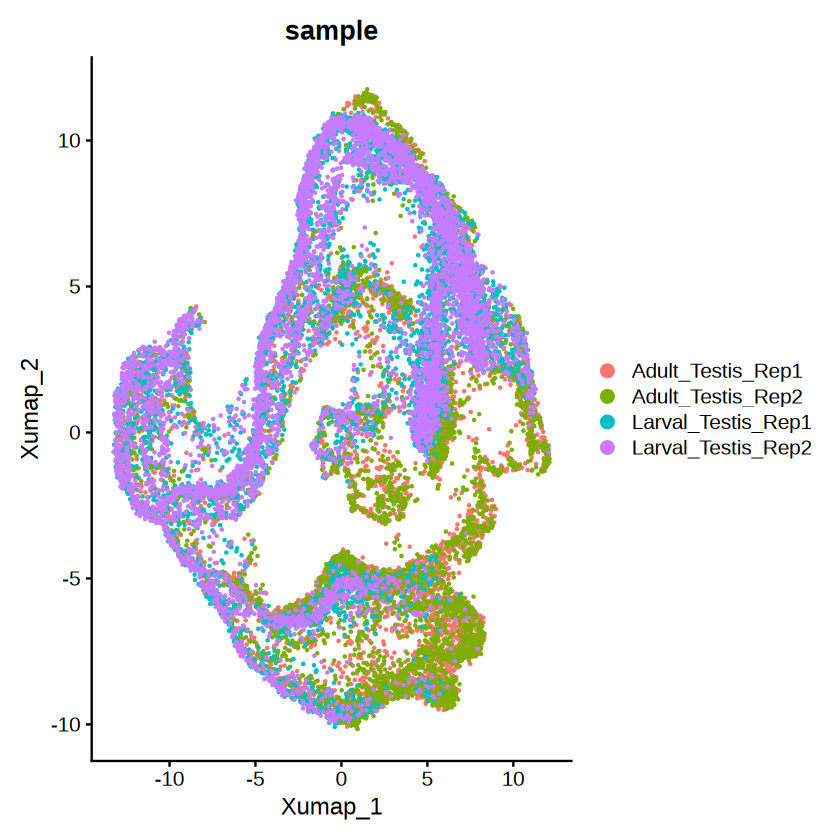

In [4]:
## plot the UMAP
sce_umap <- DimPlot(sce, reduction = "X_umap", group.by = "sample", label = FALSE)
sce_umap

In [5]:
## save the umap with raw clusters
png(file="figures/testis_raw_umap.png",
width=600, height=500)
print(sce_umap)
dev.off()

agg_record_3c186610c9e76f 
                        2

Centering and scaling data matrix

PC_ 1 
Positive:  LOC4813116, LOC4804879, LOC6901756, LOC6898401, LOC6902625, LOC6897387, LOC6903342, LOC26533720, LOC4804938, LOC6902738 
	   LOC6901511, LOC117184428, LOC4817619, LOC117184498, LOC4811655, LOC4816492, LOC117183297, LOC117184076, LOC4800569, LOC6897614 
	   LOC26532987, LOC6897611, LOC26534107, LOC4805161, LOC4800308, LOC4803974, LOC6897127, LOC4815783, LOC4802654, LOC4805073 
Negative:  LOC4805418, LOC4817707, LOC4803549, LOC4815261, LOC4814783, LOC4803147, LOC4800830, LOC4818080, LOC4800349, LOC6903891 
	   LOC4805308, LOC4803995, LOC4801366, LOC4815045, LOC6899080, LOC6900505, LOC6901942, LOC4802563, LOC4803373, LOC6901593 
	   LOC26532948, LOC4803853, LOC4805350, LOC4812733, LOC4802041, LOC4804311, LOC4805471, LOC4811643, LOC4814653, LOC26532275 
PC_ 2 
Positive:  LOC4804338, LOC4804173, LOC4811735, LOC4817984, LOC6898657, LOC4805525, LOC4805388, LOC4814494, LOC4804223, LOC117184397 
	   LOC4815533, LOC4813799, LOC4813405, LOC4804

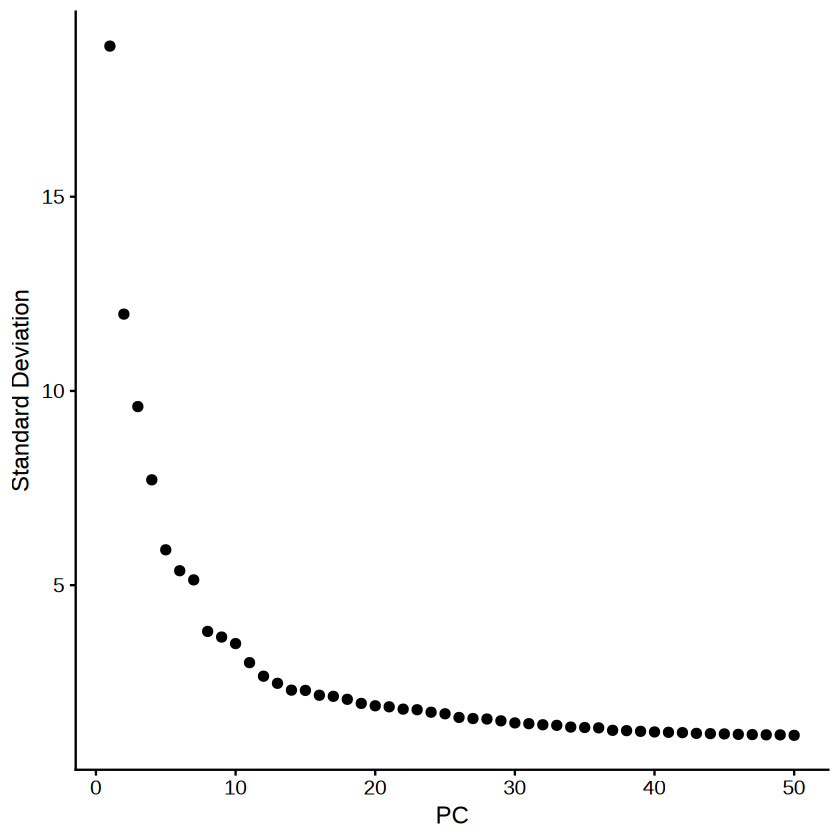

In [6]:
# ## since the data has been normalized, skip the normalization step by saving the count objects as data

## find genes that vary between cells
sce <- FindVariableFeatures(sce, selection.method = "vst", nfeatures = 2000)

## scale data
gene_list <- rownames(sce)
scaled_sce <- ScaleData(sce, features = gene_list)

## run PCA on counts (pca saved in sce[["pca"]])
pca_sce <- RunPCA(scaled_sce, features = VariableFeatures(object = scaled_sce))

## plot the dimensions of the 
ElbowPlot(pca_sce, ndims = 50)

#### Based on the Elbow graph, it looks like most of the variation is resolved by the first 30 PCs, so we will use that for downstream analysis

Computing nearest neighbor graph



Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 19236
Number of edges: 762574

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9233
Number of communities: 21
Elapsed time: 2 seconds


Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
13:17:10 UMAP embedding parameters a = 0.9922 b = 1.112

13:17:10 Read 19236 rows and found 30 numeric columns

13:17:10 Using Annoy for neighbor search, n_neighbors = 30

13:17:10 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

13:17:12 Writing NN index file to temp file /tmp/RtmpTD7K5Z/file3c18665c94eed5

13:17:12 Searching Annoy index using 1 thread, search_k = 3000

13:17:18 Annoy recall = 100%

13:17:19 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbor

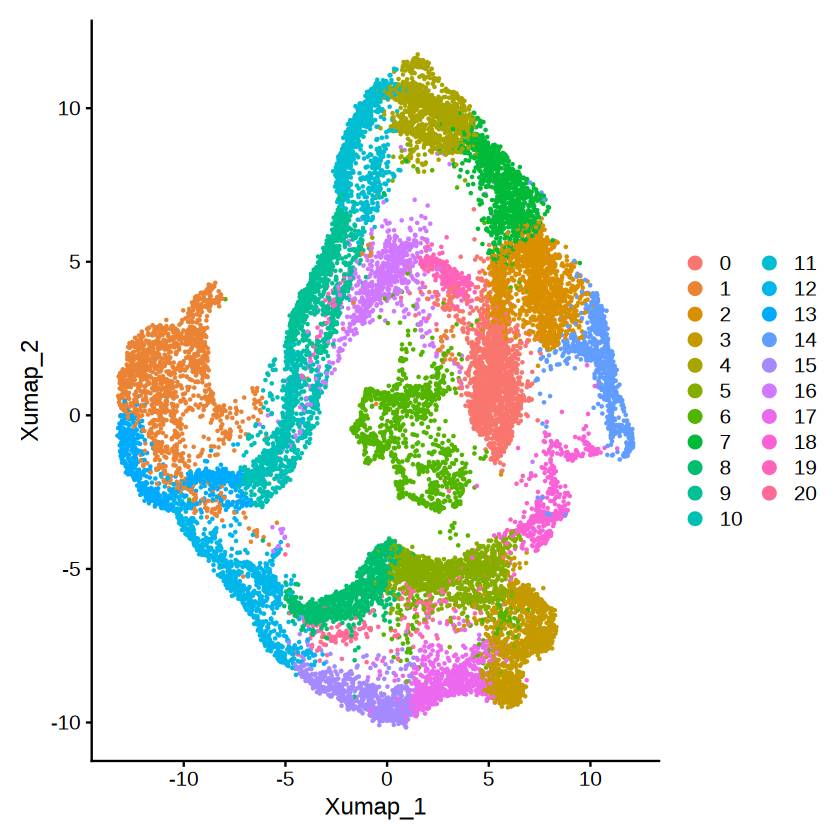

In [7]:
## find clusters, based on the first 30 PCs
cluster_sce <- FindNeighbors(pca_sce, dims = 1:30)
cluster_sce <- FindClusters(cluster_sce, resolution = 0.75)

## run UMAP and annotate with these clusters
cluster_sce <- RunUMAP(cluster_sce, dims = 1:30)

## plot the UMAP
sce_umap <- DimPlot(cluster_sce, reduction = "X_umap")
sce_umap

In [8]:
## save the umap with raw clusters
png(file="figures/testis_cluster_umap.png",
width=600, height=500)
print(sce_umap)
dev.off()

agg_record_3c18665096fe28 
                        2

## Annotate clusters

### Load in data

In [9]:
## load in results
sce_markers <- read_csv("results/pseudoobscura_testis_markers.csv")

## load in name change
dmel_dpse <- read_tsv("drosoma_pse_mel.txt", col_names = FALSE)
colnames(dmel_dpse) <- c("dpse", "dmel", "relationship", "score")

Rows: 24858 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): cluster, gene
dbl (5): p_val, avg_log2FC, pct.1, pct.2, p_val_adj

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 13772 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): X1, X2, X3
dbl (1): X4

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [10]:
## count the average number of marker genes per cluster
sce_markers %>%
    group_by(cluster) %>%
    count() %>% pull("n") %>% mean()

[1] 3107.25

In [11]:
# ## create data frame of genes from Witt et al. 2019
# dmel_testis_genes <- data.frame(stage = c("cyst", "hub", "gsc", "spermatogonia", "spermatogonia", "spermatogonia", "spermatogonia_late", "spermatocytes_early",
#                                           "spermatocytes_late", "spermatids_early", "spermatids_late", "spermatids_late", "epithelial", "epithelial"),
#                                 dmel = c("zfh1", "Fas3", "aub", "aly", "bam", "His2Av", "vasa", "fzo", "twe", "Dpy-30L2", "p-cup", "soti", "Hsp23", "MntA"))

# ## get the D. miranda counterpart for each gene
# testis_genes <- dmel_dpse %>%
#     select(dmel, dpse) %>%
#     right_join(dmel_testis_genes, by = "dmel")
# head(testis_genes)

### Get the list of marker genes for D. pseudoobscura

In [12]:
## create data frame of genes from He et al. 2026
dmel_he_testis_genes <- data.frame(stage = c("GSC/Spermatogonia", "GSC/Spermatogonia", "GSC/Spermatogonia", "GSC/Spermatogonia", "GSC/Spermatogonia",
                                            "Early Spermatocytes", "Early Spermatocytes", "Early Spermatocytes",
                                            "Late Spermatocytes", "Late Spermatocytes", "Late Spermatocytes",
                                            "Spermatid", "Spermatid",
                                            "Cyst", "Cyst",
                                            "Hub", "Epithelial", "Epithelial"),
                                   dmel = c("AGO3", "aub", "bam", "vas", "aly", "can", "sa", "CycB", "twe", "bol", "soti", "wa-cup", "f-cup",
                                            "tj", "eya", "Fas3", "MtnA", "Hsp23"))

## get the D. miranda counterpart for each gene
he_testis_genes <- dmel_dpse %>%
    select(dmel, dpse) %>%
    right_join(dmel_he_testis_genes, by = "dmel")
head(he_testis_genes)

dmel,dpse,stage
<chr>,<chr>,<chr>
f-cup,LOC6897136,Spermatid
soti,LOC4801948,Late Spermatocytes
wa-cup,LOC4802953,Spermatid
bam,LOC4803214,GSC/Spermatogonia
CycB,LOC4803852,Early Spermatocytes
AGO3,LOC26534190,GSC/Spermatogonia


In [13]:
## identify if any of the testis genes are also marker genes
sce_markers %>%
    filter(gene %in% na.omit(he_testis_genes$dpse))

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
0.000000e+00,0.7130459,1.000,0.970,0.000000e+00,Late EuC,LOC4801948
2.287620e-24,0.3007066,0.722,0.689,3.289826e-20,Late EuC,LOC4814025
0.000000e+00,2.8549767,0.407,0.082,0.000000e+00,G,LOC117183186
0.000000e+00,3.8164027,0.259,0.021,0.000000e+00,G,LOC117184134
1.607148e-235,0.9138337,0.357,0.111,2.311239e-231,G,LOC4814180
1.337097e-226,1.4679294,0.726,0.438,1.922879e-222,G,LOC26534190
4.640227e-180,0.9483177,0.208,0.048,6.673111e-176,G,LOC117184970
4.769215e-143,5.2206847,0.066,0.004,6.858608e-139,G,LOC4803214
8.900329e-62,3.0761710,0.046,0.007,1.279956e-57,G,LOC4817993


Warning message:
“The following requested variables were not found: NA”


Warning message:
“The following requested variables were not found: NA”


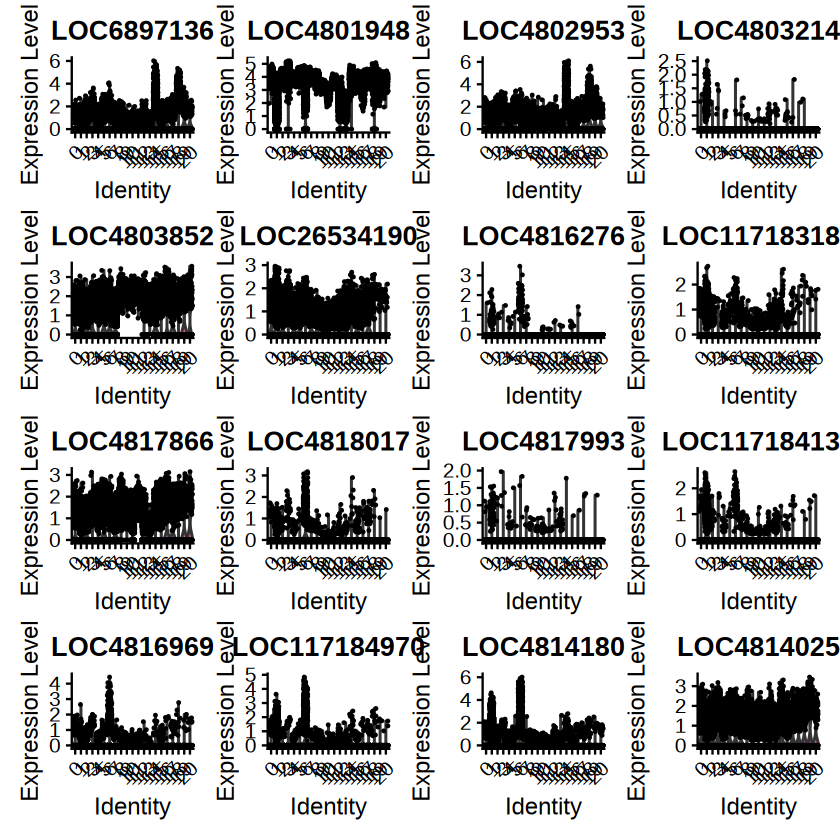

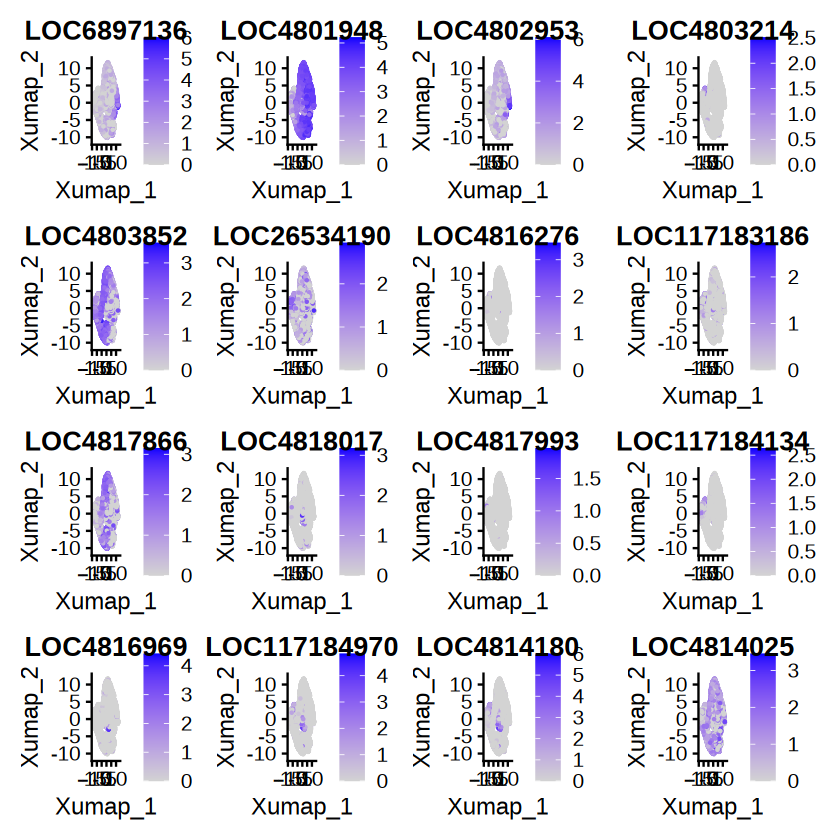

In [14]:
## visualize the expression of the marker genes
markers_violin <- VlnPlot(cluster_sce, features = he_testis_genes$dpse)
markers_umap <- FeaturePlot(cluster_sce, features = he_testis_genes$dpse)

markers_violin
markers_umap

In [15]:
## save the violin plot of marker gene expression
png(file="figures/testis_marker_violin.png",
width=1200, height=1000)
print(markers_violin)
dev.off()

agg_record_3c18662c055b87 
                        2

In [16]:
png(file="figures/testis_marker_umap.png",
width=1200, height=1000)
print(markers_umap)
dev.off()

agg_record_3c18661a1007be 
                        2

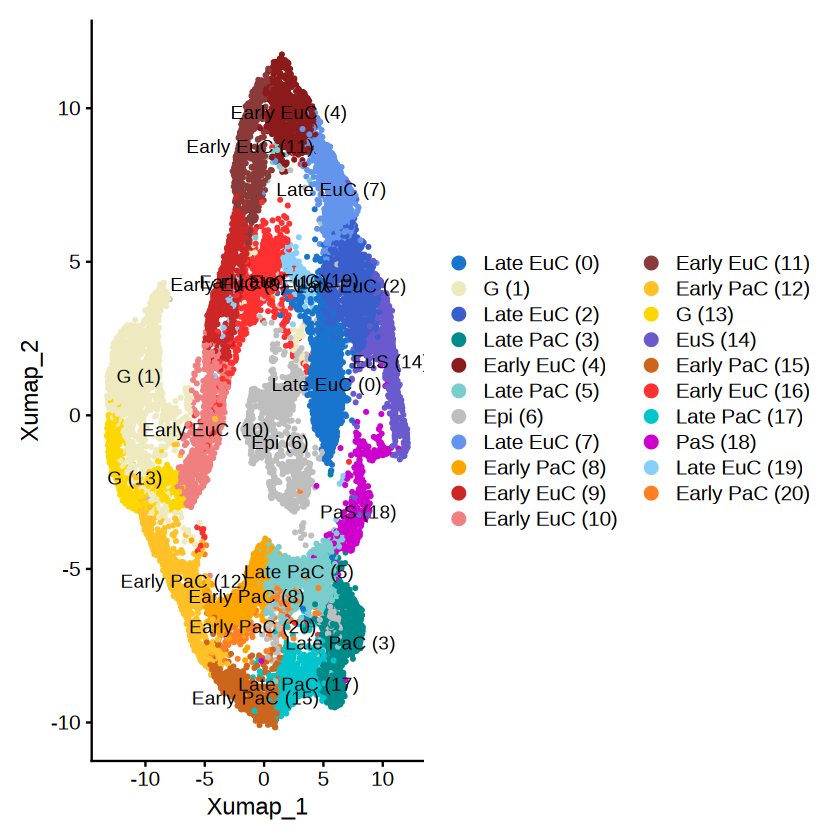

In [17]:
## save the names of the clusters
cluster_names <- c("Late EuC (0)", "G (1)", "Late EuC (2)", "Late PaC (3)", "Early EuC (4)", "Late PaC (5)", "Epi (6)", "Late EuC (7)", "Early PaC (8)", "Early EuC (9)", "Early EuC (10)", 
                   "Early EuC (11)", "Early PaC (12)", "G (13)", "EuS (14)", "Early PaC (15)", "Early EuC (16)", "Late PaC (17)", "PaS (18)", "Late EuC (19)", "Early PaC (20)")
names(cluster_names) <- levels(cluster_sce)

## annotate the clusters
annotated_sce <- RenameIdents(cluster_sce, cluster_names)

## create color palette
cluster_colors <- c("G (1)" = "lemonchiffon2", "G (13)" = "gold",
                   "Early EuC (10)" = "lightcoral", "Early EuC (9)" = "firebrick3", "Early EuC (16)" = "firebrick1", "Early EuC (11)" = "indianred4", "Early EuC (4)" = "firebrick4", 
                   "Early PaC (12)" = "goldenrod1", "Early PaC (8)" = "orange", "Early PaC (20)" = "chocolate1", "Early PaC (15)" = "chocolate3",
                   "Late EuC (19)" = "lightskyblue", "Late EuC (7)" = "cornflowerblue", "Late EuC (0)" = "dodgerblue3", "Late EuC (2)" = "royalblue3",
                   "Late PaC (5)" = "darkslategray3", "Late PaC (17)" = "turquoise3", "Late PaC (3)" = "darkcyan",
                   "EuS (14)" = "slateblue", "PaS (18)" = "magenta3",
                   "Epi (6)" = "gray")

## plot clusters, now with names
annotated_umap <- DimPlot(annotated_sce, reduction = "X_umap", cols = cluster_colors, label = TRUE, pt.size = 0.5)
annotated_umap

In [18]:
## save the annotated umap
png(file="figures/testis_annotated_umap.png",
width=1000, height=800)
print(annotated_umap)
dev.off()

agg_record_3c18665676ff72 
                        2

#### Investigate marker genes from Messer et al. 2026

In [19]:
## create data frame of genes from He et al. 2026
dmel_messer_testis_genes <- data.frame(stage = c("GSC-SG", "SG", "SG", "SG",
                                                 "SC", "SC", "SC", "SC", "SC", "SC", "SC", "SC",
                                                 "ST", "ST", "ST"),
                                       dmel = c("esg", "shg", "vas", "aly", 
                                                "wuc", "ProtA", "boule", "TGIF", "kmg", "S-Lap5", "S-Lap7", "S-Lap8",
                                                "f-cup", "wa-cup", "p-cup"))

## get the D. miranda counterpart for each gene
messer_testis_genes <- dmel_dpse %>%
    select(dmel, dpse) %>%
    right_join(dmel_messer_testis_genes, by = "dmel") %>%
    na.omit()
messer_testis_genes

dmel,dpse,stage
<chr>,<chr>,<chr>
f-cup,LOC6897136,ST
wa-cup,LOC4802953,ST
S-Lap5,LOC6898081,SC
S-Lap8,LOC4803787,SC
wuc,LOC4804758,SC
S-Lap7,LOC4805161,SC
S-Lap5,LOC4805168,SC
shg,LOC6898987,SG
esg,LOC4816405,GSC-SG


In [20]:
## identify if any of the testis genes are also marker genes
# sce_markers %>%
#     filter(gene %in% messer_testis_genes$dpse)
sce_markers %>%
    filter(gene == "LOC4811817")

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
5.421992e-20,0.1947804,0.516,0.420,7.797367e-16,G,LOC4811817
2.447730e-32,0.2094285,0.262,0.463,3.520081e-28,Late PaC,LOC4811817
3.580091e-12,0.2735807,0.238,0.438,5.148529e-08,EuS,LOC4811817
6.173060e-18,0.2840284,0.165,0.437,8.877477e-14,PaS,LOC4811817


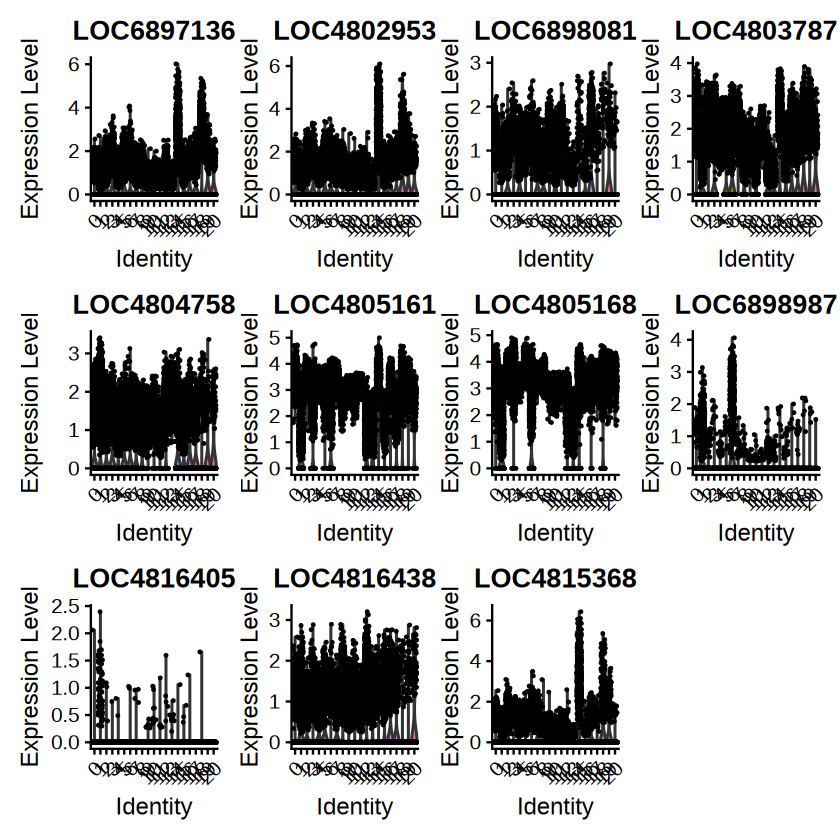

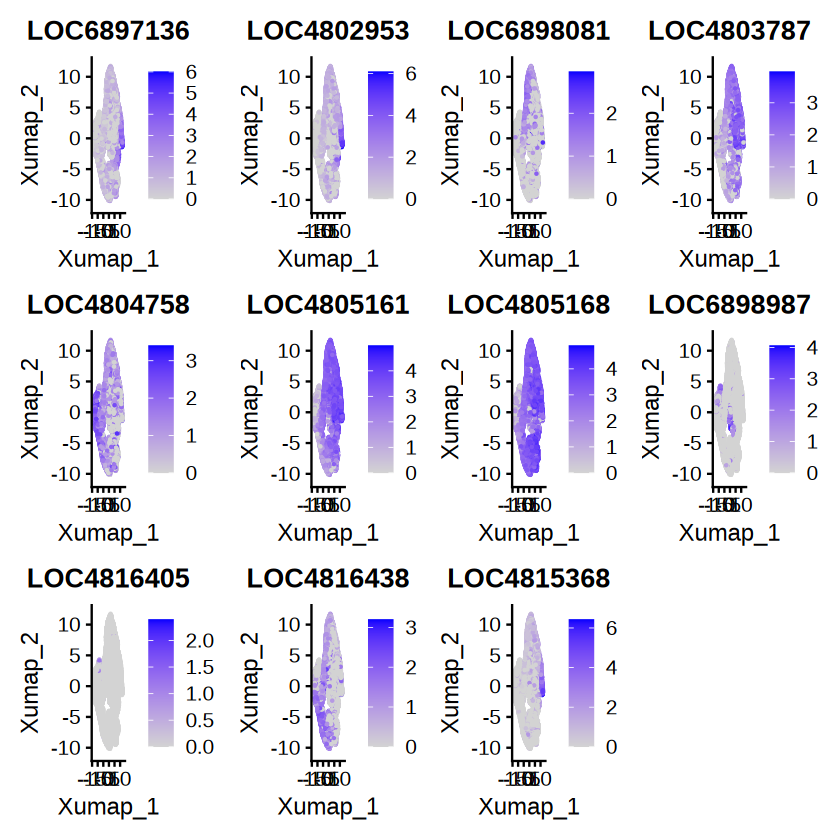

In [21]:
## visualize the expression of the marker genes
markers_violin <- VlnPlot(cluster_sce, features = messer_testis_genes$dpse)
markers_umap <- FeaturePlot(cluster_sce, features = messer_testis_genes$dpse)

markers_violin
markers_umap

### Identify eusperm versus parasperm cells

In [22]:
## save the list of eusperm biased genes from He et al. 2026
eusperm_genes <- c("salto", "tbrd-1", "eIF4E3", "fan")

## get the pseudoobscura orthologs of these genes
eusperm_genes <- dmel_dpse %>%
    select(dmel, dpse) %>%
    filter(dmel %in% eusperm_genes)
eusperm_genes

dmel,dpse
<chr>,<chr>
tbrd-1,LOC6897274
salto,LOC4803671
eIF4E3,LOC6902494
fan,LOC6902496
tbrd-1,LOC6901771
salto,LOC6901565
fan,LOC6900207
eIF4E3,LOC4814110


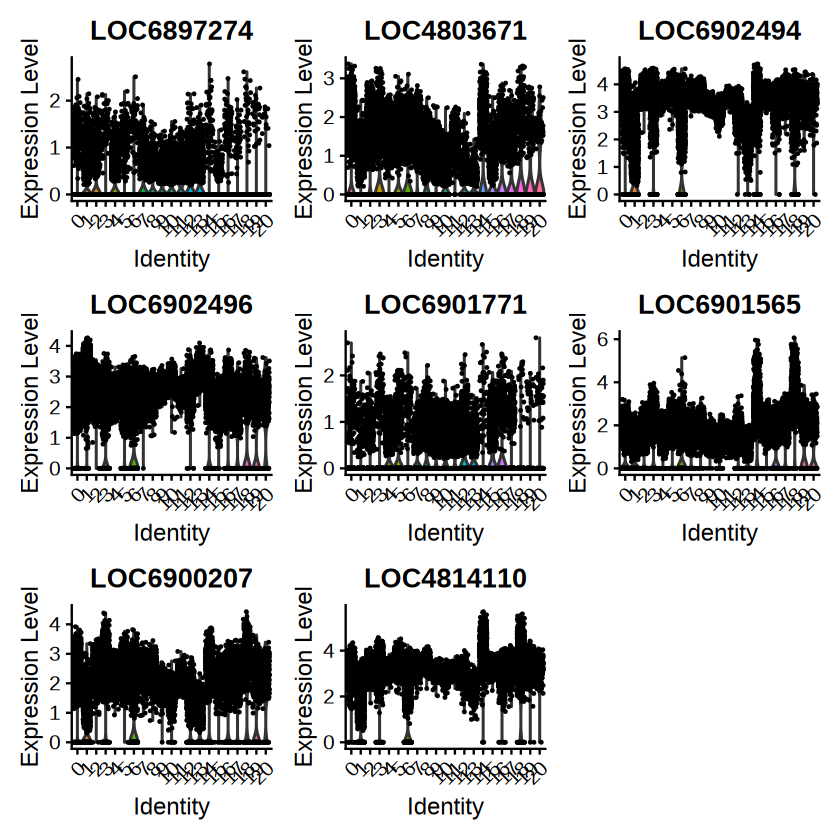

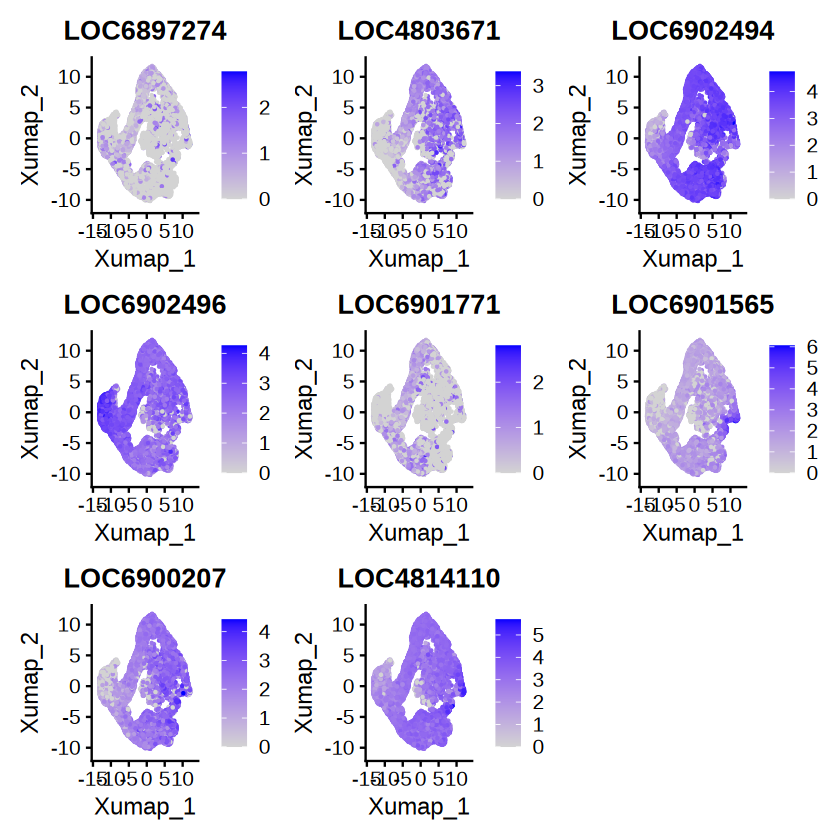

In [23]:
## identify eusperm versus parasperm clusters
eusperm_violin <- VlnPlot(cluster_sce, features = eusperm_genes$dpse)
eusperm_umap <- FeaturePlot(cluster_sce, features = eusperm_genes$dpse)

eusperm_violin
eusperm_umap

In [24]:
## save the violin plot of marker gene expression
png(file="figures/testis_eusperm_violin.png",
width=1200, height=1000)
print(eusperm_violin)
dev.off()

agg_record_3c186646ff3cc1 
                        2

In [25]:
png(file="figures/testis_eusperm_umap.png",
width=1200, height=1000)
print(eusperm_umap)
dev.off()

agg_record_3c18664c67fe5b 
                        2

## Collapse clusters based on cell type

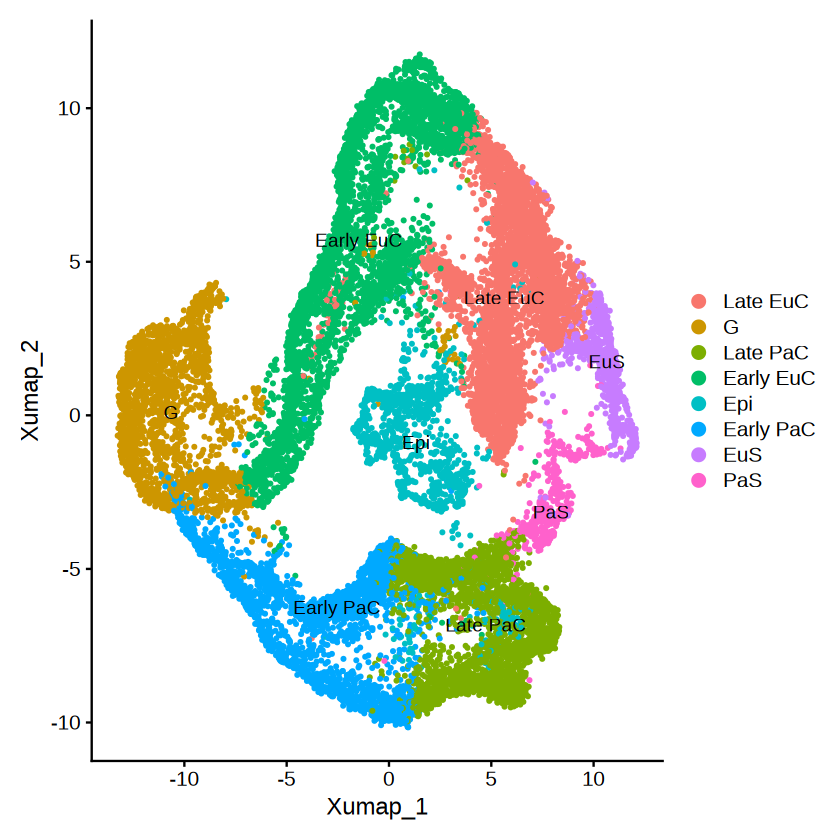

In [26]:
## reannotated clusters based on cell type
cluster_names <- c("Late EuC", "G", "Late EuC", "Late PaC", "Early EuC", "Late PaC", "Epi", "Late EuC", "Early PaC", "Early EuC", "Early EuC", 
                   "Early EuC", "Early PaC", "G", "EuS", "Early PaC", "Early EuC", "Late PaC", "PaS", "Late EuC", "Early PaC")
names(cluster_names) <- levels(cluster_sce)

## annotate the clusters
annotated_down_sce <- RenameIdents(cluster_sce, cluster_names)

## plot clusters, now with names
annotated_down_umap <- DimPlot(annotated_down_sce, reduction = "X_umap", label = TRUE, pt.size = 0.5)
annotated_down_umap

In [27]:
## get the cell stage 
cell_stages <- Idents(annotated_down_sce) %>%
    as.data.frame() %>%
    pull(1)

## add metadata column for cell stage
annotated_down_sce$stage <- cell_stages

In [28]:
saveRDS(annotated_down_sce, "results/processed_sce.rds")

## Identify genes that differ between morphs for each stage

In [30]:
## find differentially expressed genes between eusperm and parasperm for different cell types
early_c_logfc <- FindMarkers(annotated_down_sce, ident.1 = "Early EuC", ident.2 = "Early PaC", test.use = "MAST") %>%
    mutate(stage = "early_spermatocyte")
late_c_logfc <- FindMarkers(annotated_down_sce, ident.1 = "Late EuC", ident.2 = "Late PaC", test.use = "MAST") %>%
    mutate(stage = "late_spermatocyte")
sperm_logfc <- FindMarkers(annotated_down_sce, ident.1 = "EuS", ident.2 = "PaS", test.use = "MAST") %>%
    mutate(stage = "sperm")

## combine into data set
logfc_morph <- rbind(early_c_logfc, late_c_logfc, sperm_logfc)
write_csv(logfc_morph, "results/logfc_morph_stage.csv")


Done!

Combining coefficients and standard errors

Calculating log-fold changes

Calculating likelihood ratio tests

Refitting on reduced model...


Done!


Done!

Combining coefficients and standard errors

Calculating log-fold changes

Calculating likelihood ratio tests

Refitting on reduced model...


Done!


Done!

Combining coefficients and standard errors

Calculating log-fold changes

Calculating likelihood ratio tests

Refitting on reduced model...


Done!



## Identify enriched GO terms among cluster markers

In [31]:
## get the list of GO terms
ontology <- read_csv("../trinotate/dpse_goterms.csv")
head(ontology)

New names:
• `` -> `...1`
Rows: 915220 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): gene, term, category
dbl (1): ...1

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


...1,gene,term,category
<dbl>,<chr>,<chr>,<chr>
1,HCS66_mgp01,catalytic activity,molecular_function
2,HCS66_mgp01,cytochrome-c oxidase activity,molecular_function
3,HCS66_mgp01,transporter activity,molecular_function
4,HCS66_mgp01,binding,molecular_function
5,HCS66_mgp01,copper ion binding,molecular_function
6,HCS66_mgp01,cellular_component,molecular_function


In [32]:
# ### determine if there is enrichment of GO terms among the early spermatocyte markers, and differences between the parasperm and eusperm clusters

# ## create the lists to iterate through
# go_terms <- unique(ontology$term)
# marker_clusters <- unique(sce_markers$cluster)

# ## create empty data frame to populate
# go_compared <- data.frame(go_term = character(),
#                           cluster = character(),
#                           go_genes = double(),
#                           go_ratio = double(),
#                           go_pvalue = double())

# ## populate the data frame
# for (i in go_terms) {
#     for (j in marker_clusters) {
    
#         ## list of marker genes
#         cluster_markers <- sce_markers %>%
#             filter(cluster == j) %>%
#             pull("gene")

#         ## format dataframe based on mutation type and associated go term
#         go_df <- ontology %>%
#             mutate(signif = case_when(gene %in% cluster_markers ~ "signif",
#                                     TRUE ~ "nontype"),
#                 go = case_when(term == i ~ "go",
#                                 TRUE ~ "nogo")) %>%
#             group_by(signif, go) %>%
#             count() %>%
#             pivot_wider(names_from = go, values_from = n) %>%
#             column_to_rownames("signif") %>%
#             mutate_all(replace_na, replace = 0)

#         ## get the number of genes with both mutation type and go term
#         signif_go <- go_df["signif", "go"]

#         ## only perform chi squared if there are more than 0 genes with go term
#         if (signif_go > 0) {        
            
#             ## perform chi-squared test
#             go_chi <- go_df %>%
#                 as.matrix() %>%
#                 chisq.test()
#             go_pvalue <- go_chi$p.value

#             ## populate dataframe with data
#             go_compared <- add_row(go_compared, go_term = i, 
#                                                 cluster = j,
#                                                 go_genes = signif_go, 
#                                                 go_ratio = signif_go/length(cluster_markers), 
#                                                 go_pvalue = go_pvalue)
            
#         } 
#     }
# }

# ## perform multiple testing correction
# go_compared$pvalue_corrected <- p.adjust(go_compared$go_pvalue, method = "BH")

# ## write document
# write_csv(go_compared, "results/spermatogenesis_markers_go.csv")